In [1]:
import sys
import os
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt, colors, patches

from sklearn.preprocessing import StandardScaler
from sklearn.cross_decomposition import CCA


sys.path.append(os.path.join(os.getcwd(), '../../'))
from utils import read_utils
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/fly-2023-schaffer/data_exploration/manifold/../../utils/train_utils.py'>

In [3]:
read_ids = list(range(0, 12+1))
# read_ids = [0, 2, 3, 8, 9]
plot_id = 0

dims = 3
dims_preca = 5

selection_n = 5
selection_bhl = ['still', 'walk', 'front-groom', 'back-groom', 'abdomen-move']

In [4]:
path = os.path.join(read_utils.get_data_path(), 'fly-2023-schaffer/brain')

(file_ids, filenames,
 traces,
 states, markers) = read_utils.get_data(path, read_ids)

# # clear nan values
# for i in range(len(file_ids)):
# 	mask = markers[i].notna().all(axis=1)
#
# 	traces[i] = traces[i][mask]
# 	markers[i] = markers[i][mask]
# 	states[i] = states[i][mask]
#
# 	#filenames[i] = filenames[i][mask]

# # remove unused discrete state labels
# states = [ds[selection_bhl] for ds in states]

# naive ID unknown neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces[i].columns, traces[i].columns == ''))
	])

# man

In [5]:
(modes_manifold, modes_manifold_b,
 recos_manifold, recos_manifold_b,
 loads_cca_man, loads_cca_man_b,
 vars_expl_mans, vars_expl_mans_rs) = train_utils.get_manifolds_cca(traces,
																	[ds[selection_bhl] for ds in states],
																	n_cv=dims, n_pc=dims_preca)

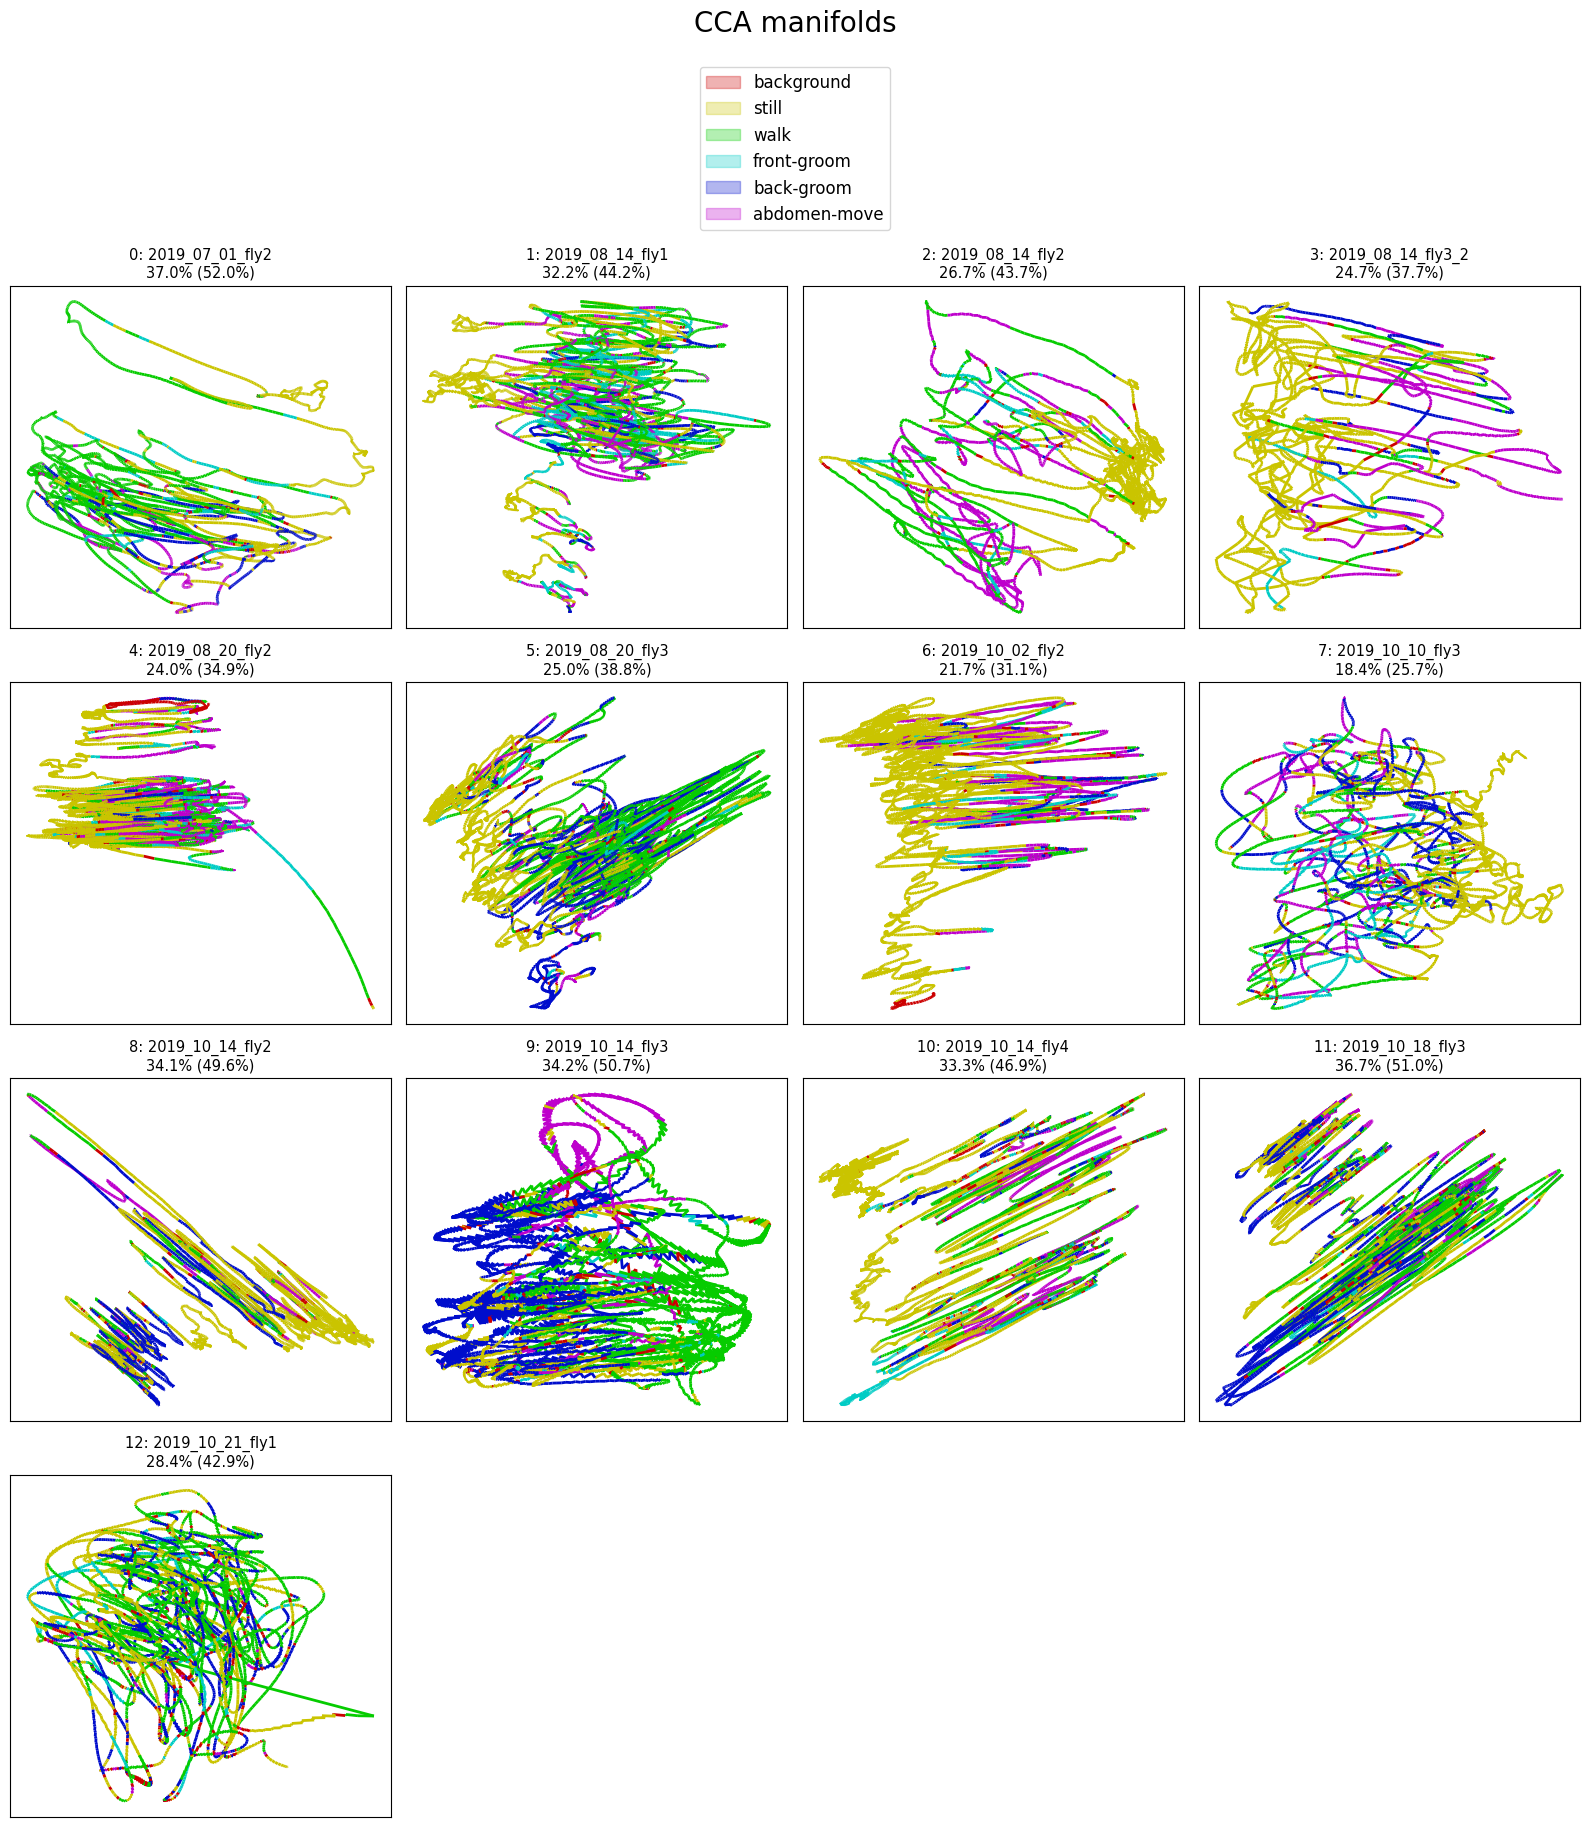

28.9% (21.1%)


In [6]:
plot_utils.plot_manifolds([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
						  modes_manifold, states,
						  [vx[:2] for vx in vars_expl_mans], [vx[:2] for vx in vars_expl_mans_rs] if dims_preca > 0 else None,
						  title='CCA manifolds', top_space=2.5, save_name=None)  #f'{f'{dims_preca}-dim-PCA_' if dims_preca > 0 else ''}{dims}-dim-CCA'

In [7]:
# plot_utils.plot_manifolds_3d([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
# 							 modes_manifold, [ds[selection_bhl] for ds in states],
# 							 [vx[:3] for vx in vars_expl_mans], [vx[:3] for vx in vars_expl_mans_rs] if dims_preca > 0 else None,
# 							 title='CCA manifolds', save_name=None)  #f'{f'{dims_preca}-dim-PCA_' if dims_preca > 0 else ''}{dims}-dim-CCA_3d'

In [8]:
for file_id in file_ids:
	corrs = [
		np.corrcoef(modes_manifold[file_ids.index(file_id)].values[:, i], modes_manifold_b[file_ids.index(file_id)].values[:, i])[0, 1] for i in range(modes_manifold[file_ids.index(file_id)].values.shape[1])
	]
	print(f'{file_id}: {filenames[file_ids.index(file_id)]}')
	for i, corr in enumerate(corrs):
		print(f'\tCV{i}: {corr:.2f}')

0: 2019_07_01_fly2
	CV0: 0.76
	CV1: 0.40
	CV2: 0.17
1: 2019_08_14_fly1
	CV0: 0.60
	CV1: 0.15
	CV2: 0.11
2: 2019_08_14_fly2
	CV0: 0.83
	CV1: 0.24
	CV2: 0.15
3: 2019_08_14_fly3_2
	CV0: 0.69
	CV1: 0.16
	CV2: 0.08
4: 2019_08_20_fly2
	CV0: 0.70
	CV1: 0.26
	CV2: 0.11
5: 2019_08_20_fly3
	CV0: 0.70
	CV1: 0.28
	CV2: 0.10
6: 2019_10_02_fly2
	CV0: 0.67
	CV1: 0.23
	CV2: 0.13
7: 2019_10_10_fly3
	CV0: 0.64
	CV1: 0.19
	CV2: 0.15
8: 2019_10_14_fly2
	CV0: 0.53
	CV1: 0.34
	CV2: 0.06
9: 2019_10_14_fly3
	CV0: 0.70
	CV1: 0.42
	CV2: 0.22
10: 2019_10_14_fly4
	CV0: 0.71
	CV1: 0.43
	CV2: 0.17
11: 2019_10_18_fly3
	CV0: 0.53
	CV1: 0.30
	CV2: 0.12
12: 2019_10_21_fly1
	CV0: 0.32
	CV1: 0.18
	CV2: 0.08


In [9]:
raise Exception

Exception: 

# residuals

In [ ]:
markers_zs = [pd.DataFrame(data=StandardScaler().fit_transform(marker.values), columns=marker.columns) for marker in markers]

In [ ]:
traces_residual = [pd.DataFrame(data=trace - reco_man, columns=trace.columns) for trace, reco_man in zip(traces, recos_manifold)]

In [ ]:
# for t_res in traces_residual:
# 	print(np.median(t_res.values, axis=0))

In [ ]:
n_cv = markers_zs[file_ids.index(plot_id)].values.shape[1]

(modes_concrete, modes_concrete_b,
 recos_concrete, recos_concrete_b,
 loads_cca_con, loads_cca_con_b,
 vars_expl_cons, vars_expl_cons_rs) = train_utils.get_manifolds_cca(traces_residual,
																	markers_zs,
																	n_cv=n_cv, n_pc=0)

In [ ]:
plot_utils.plot_manifolds([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
						  modes_concrete, markers_zs,
						  [vx[:2] for vx in vars_expl_cons], None,
						  title='CCA concretes', save_name=None, top_space=6)

In [ ]:
plot_utils.plot_manifolds([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
						  modes_concrete_b, markers_zs,
						  [vx[:2] for vx in vars_expl_cons], None,
						  title='CCA concretes b', save_name=None, top_space=7)

In [ ]:
for file_id in file_ids:
	corrs = [
		np.corrcoef(modes_concrete[file_ids.index(file_id)].values[:, i], modes_concrete_b[file_ids.index(file_id)].values[:, i])[0, 1] for i in range(modes_concrete[file_ids.index(file_id)].values.shape[1])
	]
	print(f'{filenames[file_ids.index(file_id)]}')
	for i, corr in enumerate(corrs):
		print(f'\tCV{i}: {corr:.2f}')